[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-cheminformatics-course/blob/main/notebooks/02_rdkit_basics.ipynb)

# 02 · RDKit Basics: SMILES, Molecules, and Drawing

*Practical Cheminformatics Course · Hamza Hentabli, Ph.D. · ~50 min*

[RDKit](https://www.rdkit.org) is the open-source cheminformatics toolkit used throughout
academia and the pharmaceutical industry. In this notebook you will learn its core object,
the `Mol`, and the identifiers chemists use to exchange structures.

**Learning objectives.** By the end of this notebook you will be able to:

- explain what a SMILES string encodes
- turn SMILES into RDKit `Mol` objects and handle invalid input
- inspect atoms, bonds, and rings
- produce canonical SMILES, InChI, and InChIKey identifiers
- draw single molecules and grids of molecules

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Install requirements.txt once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'rdkit'], check=True)
    if not os.path.isdir("practical-cheminformatics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-cheminformatics-course.git"], check=True)
    DATA_DIR = "practical-cheminformatics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. SMILES in a nutshell

SMILES (Simplified Molecular Input Line Entry System) writes a molecule as text:

| SMILES | Meaning |
|---|---|
| `C`, `N`, `O` | aliphatic atoms (implicit hydrogens added automatically) |
| `c`, `n`, `o` | aromatic atoms |
| `=`, `#` | double and triple bonds |
| `( )` | branches |
| `1 … 1` | ring closure |
| `[NH4+]`, `[O-]` | atoms with explicit charge or hydrogens in brackets |

Example: aspirin is `CC(=O)Oc1ccccc1C(=O)O`.

RDKit version: 2026.09.2


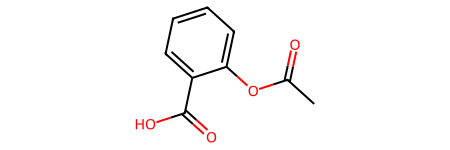

In [2]:
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw, Descriptors, rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole   # pretty molecule rendering in notebooks
import rdkit
print("RDKit version:", rdkit.__version__)

aspirin = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")
aspirin

## 2. Atoms and bonds

In [3]:
print("heavy atoms:", aspirin.GetNumAtoms())
print("bonds:      ", aspirin.GetNumBonds())
print("formula:    ", rdMolDescriptors.CalcMolFormula(aspirin))
print("mol. weight:", round(Descriptors.MolWt(aspirin), 2))

heavy atoms: 13
bonds:       13
formula:     C9H8O4
mol. weight: 180.16


In [4]:
for atom in aspirin.GetAtoms():
    print(atom.GetIdx(), atom.GetSymbol(), "aromatic" if atom.GetIsAromatic() else "",
          "| degree", atom.GetDegree(), "| implicit H", atom.GetTotalNumHs())

0 C  | degree 1 | implicit H 3
1 C  | degree 3 | implicit H 0
2 O  | degree 1 | implicit H 0
3 O  | degree 2 | implicit H 0
4 C aromatic | degree 3 | implicit H 0
5 C aromatic | degree 2 | implicit H 1
6 C aromatic | degree 2 | implicit H 1
7 C aromatic | degree 2 | implicit H 1
8 C aromatic | degree 2 | implicit H 1
9 C aromatic | degree 3 | implicit H 0
10 C  | degree 3 | implicit H 0
11 O  | degree 1 | implicit H 0
12 O  | degree 1 | implicit H 1


In [5]:
for bond in list(aspirin.GetBonds())[:6]:
    print(bond.GetBeginAtomIdx(), "-", bond.GetEndAtomIdx(), bond.GetBondType())

0 - 1 SINGLE
1 - 2 DOUBLE
1 - 3 SINGLE
3 - 4 SINGLE
4 - 5 AROMATIC
5 - 6 AROMATIC


In [6]:
ri = aspirin.GetRingInfo()
print("number of rings:", ri.NumRings(), "| atoms in ring:", ri.AtomRings())

number of rings: 1 | atoms in ring: ((4, 5, 6, 7, 8, 9),)


Hydrogens are *implicit* by default. Add them explicitly when you need 3D coordinates or H counts per atom.

In [7]:
aspirin_h = Chem.AddHs(aspirin)
print(aspirin.GetNumAtoms(), "→", aspirin_h.GetNumAtoms(), "atoms after AddHs")

13 → 21 atoms after AddHs


## 3. One molecule, many SMILES: canonicalization

The same molecule can be written many ways. RDKit's **canonical SMILES** is unique for a given
structure (within one RDKit version), which makes it useful for comparing and deduplicating.

In [8]:
variants = ["OC(=O)c1ccccc1OC(C)=O", "CC(=O)Oc1ccccc1C(O)=O", "O=C(O)c1ccccc1OC(=O)C"]
for s in variants:
    print(f"{s:<26} → {Chem.MolToSmiles(Chem.MolFromSmiles(s))}")

OC(=O)c1ccccc1OC(C)=O      → CC(=O)Oc1ccccc1C(=O)O
CC(=O)Oc1ccccc1C(O)=O      → CC(=O)Oc1ccccc1C(=O)O
O=C(O)c1ccccc1OC(=O)C      → CC(=O)Oc1ccccc1C(=O)O


## 4. InChI and InChIKey

The IUPAC **InChI** is a standard, toolkit-independent identifier. The **InChIKey** is its
27-character hash, perfect for database lookups and duplicate detection.

In [9]:
print(Chem.MolToInchi(aspirin))
print(Chem.MolToInchiKey(aspirin))

InChI=1S/C9H8O4/c1-6(10)13-8-5-3-2-4-7(8)9(11)12/h2-5H,1H3,(H,11,12)
BSYNRYMUTXBXSQ-UHFFFAOYSA-N


## 5. Invalid SMILES

Real datasets contain broken structures. `MolFromSmiles` returns `None` instead of raising an
error, so **always check**. Here we silence RDKit's warnings to keep the output tidy.

In [10]:
RDLogger.DisableLog("rdApp.*")
for s in ["c1ccccc1", "c1cccc1", "C(C)(C)(C)(C)C", "CC(=O"]:
    m = Chem.MolFromSmiles(s)
    print(f"{s:<16}", "OK" if m is not None else "INVALID")

c1ccccc1         OK
c1cccc1          INVALID
C(C)(C)(C)(C)C   INVALID
CC(=O            INVALID


`c1cccc1` fails because a five-membered all-carbon ring cannot be aromatic, and
`C(C)(C)(C)(C)C` has a pentavalent carbon.

## 6. Drawing molecules

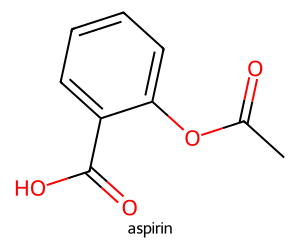

In [11]:
Draw.MolToImage(aspirin, size=(300, 250), legend="aspirin")

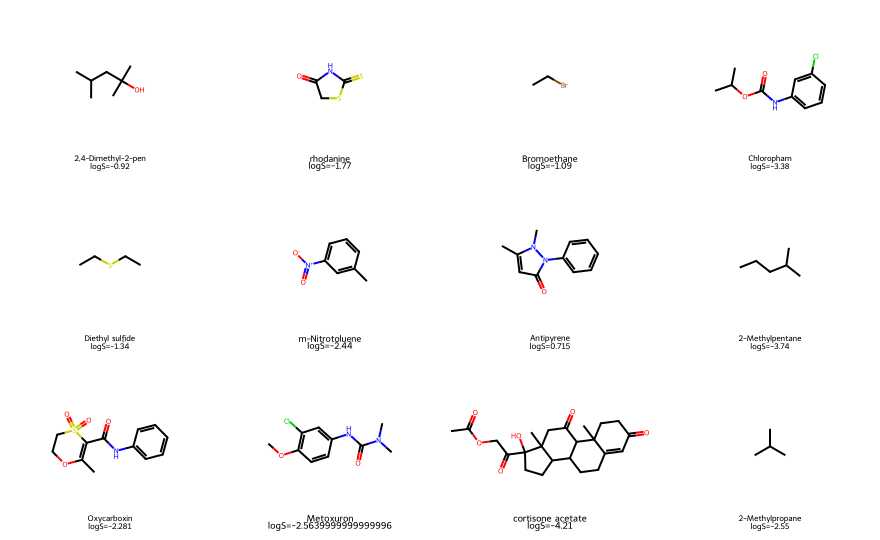

In [12]:
import pandas as pd
esol = pd.read_csv(f"{DATA_DIR}/esol_delaney.csv")
sample = esol.sample(12, random_state=0)
mols = [Chem.MolFromSmiles(s) for s in sample["smiles"]]
legends = [f"{n[:18]}\nlogS={v}" for n, v in zip(sample["compound_id"], sample["logS"])]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(220, 180), legends=legends)

## 7. Adding molecules to a DataFrame

A common pattern: keep a column of `Mol` objects next to the original data.

In [13]:
esol["mol"] = esol["smiles"].apply(Chem.MolFromSmiles)
print("unparseable SMILES:", esol["mol"].isna().sum())
esol["heavy_atoms"] = esol["mol"].apply(lambda m: m.GetNumHeavyAtoms())
esol["canonical_smiles"] = esol["mol"].apply(Chem.MolToSmiles)
esol[["compound_id", "smiles", "canonical_smiles", "heavy_atoms"]].head()

unparseable SMILES: 0


,compound_id,smiles,canonical_smiles,heavy_atoms
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,N#CC(OC1OC(COC2OC(CO)C(O)C(O)C2O)C(O)C(O)C1O)c...,32
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,Cc1occc1C(=O)Nc1ccccc1,15
2,citral,CC(C)=CCCC(C)=CC(=O),CC(C)=CCCC(C)=CC=O,11
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,c1ccc2c(c1)ccc1c2ccc2c3ccccc3ccc21,22
4,Thiophene,c1ccsc1,c1ccsc1,5


### ✏️ Exercise 1

Write ethanol in three different ways (`CCO`, `OCC`, `C(O)C`) and show that they give the same canonical SMILES.

In [14]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
forms = ["CCO", "OCC", "C(O)C"]
canon = {Chem.MolToSmiles(Chem.MolFromSmiles(s)) for s in forms}
print(canon, "→ identical:", len(canon) == 1)
```

</details>

### ✏️ Exercise 2

Caffeine is `Cn1cnc2c1c(=O)n(C)c(=O)n2C`. How many nitrogen atoms does it contain, and how many of them are aromatic?

In [15]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
caffeine = Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C")
n_atoms = [a for a in caffeine.GetAtoms() if a.GetSymbol() == "N"]
print("N atoms:", len(n_atoms), "| aromatic N:", sum(a.GetIsAromatic() for a in n_atoms))
```

</details>

### ✏️ Exercise 3

Are there duplicate structures in ESOL? Count how many canonical SMILES occur more than once.

In [16]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
dup_counts = esol["canonical_smiles"].value_counts()
print((dup_counts > 1).sum(), "canonical SMILES appear more than once")
# Note: some "duplicates" (e.g. mannitol and sorbitol) are different stereoisomers whose
# SMILES in this dataset carry no stereochemistry, so they collapse to the same structure.
esol[esol["canonical_smiles"].isin(dup_counts[dup_counts > 1].index)].sort_values("canonical_smiles")[["compound_id", "canonical_smiles", "logS"]].head(10)
```

</details>

## Key takeaways

- `Chem.MolFromSmiles` → `Mol` object, or `None` for invalid input. Always check.
- Canonical SMILES and InChIKeys let you compare structures written differently.
- `Draw.MolsToGridImage` is the fastest way to *look* at your data, and you should look often.

**Next:** [03 · Descriptors and drug-likeness](03_descriptors_druglikeness.ipynb).